# Praktik Recipe 2.4 dan Recipe 
## Audit QA/QC Data Stasiun dan Pengolahan Data Gempa

**Acuan:** AI Cookbook untuk Earth Sciences, Bagian 2.4
**Recipe buku:** R-IO-001
**Recipe pengembangan:** R-GEO-001

Notebook ini berisi dua praktik:
1. Audit QA/QC data stasiun berdasarkan konsep Recipe 2.4.
2. Pengembangan recipe sendiri untuk pemeriksaan waktu tiba gelombang P dan S serta estimasi jarak berdasarkan selisih waktu tiba.

Data latihan pada notebook ini bersifat sintetis dan bukan data observasi lapangan.

## — RECIPE 2.4 

### 1. Problem

Memeriksa kualitas tabel pengamatan stasiun sebelum digunakan untuk analisis lanjutan. Pemeriksaan meliputi struktur kolom, rentang waktu, missing value, timestamp duplikat, dan ringkasan numerik.

### 2. Minimal Theory

QA/QC merupakan pemeriksaan kualitas data sebelum analisis. Timestamp duplikat perlu ditinjau karena dapat menyebabkan catatan dihitung lebih dari sekali. Missing value menunjukkan bahwa suatu nilai tidak tersedia.

### 3. Input dan Batasan

Data latihan memiliki kolom station_id, time, temperature_c, dan rainfall_mm. Data asli tidak dihapus, tidak dilakukan imputasi, dan zona waktu tidak diasumsikan.

### 4. Prompt Reusable

Bertindak sebagai scientific Python developer. Audit data stasiun dengan memeriksa struktur kolom, rentang waktu, missing value, timestamp duplikat, dan ringkasan numerik. Jangan menghapus baris atau mengisi nilai kosong secara otomatis. Jelaskan hasil berdasarkan pemeriksaan yang dilakukan.

### 5. Workflow

Problem → Minimal Theory → Prompt → Code → Result → Optional Check

In [1]:
import pandas as pd
from IPython.display import display
from pathlib import Path

data = {
    "station_id": ["ST01", "ST01", "ST01", "ST01", "ST01"],
    "time": [
        "2026-01-01 00:00",
        "2026-01-02 00:00",
        "2026-01-02 00:00",
        "2026-01-04 00:00",
        "2026-01-05 00:00"
    ],
    "temperature_c": [27.1, 27.5, None, 28.0, 27.8],
    "rainfall_mm": [0.0, 2.4, 2.4, 0.0, 1.1]
}

df = pd.DataFrame(data)
df_original = df.copy(deep=True)

display(df)
print("Jumlah baris:", len(df))
print("Kolom:", list(df.columns))

,station_id,time,temperature_c,rainfall_mm
0,ST01,2026-01-01 00:00,27.1,0.0
1,ST01,2026-01-02 00:00,27.5,2.4
2,ST01,2026-01-02 00:00,NaN,2.4
3,ST01,2026-01-04 00:00,28.0,0.0
4,ST01,2026-01-05 00:00,27.8,1.1


Jumlah baris: 5
Kolom: ['station_id', 'time', 'temperature_c', 'rainfall_mm']


In [2]:
required_columns = [
    "station_id", "time", "temperature_c", "rainfall_mm"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

parsed_time = pd.to_datetime(df["time"], errors="coerce")

time_parse_failures = int(parsed_time.isna().sum())
duplicate_rows = int(
    parsed_time.duplicated(keep=False).sum()
)

missing_values = df.isna().sum()
numeric_summary = df[
    ["temperature_c", "rainfall_mm"]
].describe()

print("=== STRUKTUR DATA ===")
print("Kolom wajib hilang:", missing_columns)
print("Jumlah baris:", len(df))
print("Jumlah stasiun:", df["station_id"].nunique())

print("\n=== RENTANG WAKTU ===")
print("Awal:", parsed_time.min())
print("Akhir:", parsed_time.max())
print("Waktu gagal diparse:", time_parse_failures)
print("Baris yang terlibat dalam timestamp duplikat:", duplicate_rows)

print("\n=== MISSING VALUE ===")
display(missing_values.to_frame("missing_count"))

print("\n=== RINGKASAN NUMERIK ===")
display(numeric_summary)

=== STRUKTUR DATA ===
Kolom wajib hilang: []
Jumlah baris: 5
Jumlah stasiun: 1

=== RENTANG WAKTU ===
Awal: 2026-01-01 00:00:00
Akhir: 2026-01-05 00:00:00
Waktu gagal diparse: 0
Baris yang terlibat dalam timestamp duplikat: 2

=== MISSING VALUE ===


,missing_count
station_id,0
time,0
temperature_c,1
rainfall_mm,0



=== RINGKASAN NUMERIK ===


,temperature_c,rainfall_mm
count,4.000000,5.000000
mean,27.600000,1.180000
std,0.391578,1.200833
min,27.100000,0.000000
25%,27.400000,0.000000
50%,27.650000,1.100000
75%,27.850000,2.400000
max,28.000000,2.400000


In [3]:
audit_table = df.copy()

audit_table["parsed_time"] = parsed_time
audit_table["flag_missing_temperature"] = (
    df["temperature_c"].isna()
)
audit_table["flag_duplicate_timestamp"] = (
    parsed_time.duplicated(keep=False)
)
audit_table["flag_time_parse_failure"] = (
    parsed_time.isna()
)

display(audit_table)

flag_columns = [
    "flag_missing_temperature",
    "flag_duplicate_timestamp",
    "flag_time_parse_failure"
]

flagged_rows = audit_table[
    audit_table[flag_columns].any(axis=1)
]

print("Jumlah baris yang perlu ditinjau:", len(flagged_rows))
display(flagged_rows)

,station_id,time,temperature_c,rainfall_mm,parsed_time,flag_missing_temperature,flag_duplicate_timestamp,flag_time_parse_failure
0,ST01,2026-01-01 00:00,27.1,0.0,2026-01-01,False,False,False
1,ST01,2026-01-02 00:00,27.5,2.4,2026-01-02,False,True,False
2,ST01,2026-01-02 00:00,NaN,2.4,2026-01-02,True,True,False
3,ST01,2026-01-04 00:00,28.0,0.0,2026-01-04,False,False,False
4,ST01,2026-01-05 00:00,27.8,1.1,2026-01-05,False,False,False


Jumlah baris yang perlu ditinjau: 2


,station_id,time,temperature_c,rainfall_mm,parsed_time,flag_missing_temperature,flag_duplicate_timestamp,flag_time_parse_failure
1,ST01,2026-01-02 00:00,27.5,2.4,2026-01-02,False,True,False
2,ST01,2026-01-02 00:00,NaN,2.4,2026-01-02,True,True,False


In [4]:
report_a = f"""# Laporan QA/QC Data Stasiun

## Ringkasan
- Jumlah baris: {len(df)}
- Jumlah kolom: {len(df.columns)}
- Rentang waktu: {parsed_time.min()} sampai {parsed_time.max()}
- Kegagalan parsing waktu: {time_parse_failures}
- Baris yang terlibat dalam timestamp duplikat: {duplicate_rows}

## Missing Value

{missing_values.to_string()}

## Interpretasi

Data latihan mengandung nilai temperatur kosong dan timestamp
berulang. Temuan tersebut perlu ditinjau sebelum analisis lanjutan.
Tidak ada baris yang dihapus dan tidak ada nilai yang diimputasi.

Data ini merupakan simulasi, bukan observasi lapangan.
"""

print(report_a)

Path("station-summary.md").write_text(
    report_a, encoding="utf-8"
)

print("Laporan tersimpan sebagai station-summary.md")

# Laporan QA/QC Data Stasiun

## Ringkasan
- Jumlah baris: 5
- Jumlah kolom: 4
- Rentang waktu: 2026-01-01 00:00:00 sampai 2026-01-05 00:00:00
- Kegagalan parsing waktu: 0
- Baris yang terlibat dalam timestamp duplikat: 2

## Missing Value

station_id       0
time             0
temperature_c    1
rainfall_mm      0

## Interpretasi

Data latihan mengandung nilai temperatur kosong dan timestamp
berulang. Temuan tersebut perlu ditinjau sebelum analisis lanjutan.
Tidak ada baris yang dihapus dan tidak ada nilai yang diimputasi.

Data ini merupakan simulasi, bukan observasi lapangan.

Laporan tersimpan sebagai station-summary.md


### 6. Result

Audit menampilkan struktur data, rentang waktu, missing value, timestamp duplikat, dan statistik numerik. Baris yang memerlukan peninjauan diberi tanda agar dapat diperiksa lebih lanjut.

### 7. Optional Check

Pemeriksaan dilakukan untuk memastikan jumlah baris tetap sama dan data sumber tidak berubah selama audit.

In [6]:
assert len(df) == len(df_original)
pd.testing.assert_frame_equal(df, df_original)

assert Path("station-summary.md").exists()
assert Path("station-summary.md").stat().st_size > 0

print("Verifikasi data sumber: LULUS")
print("Laporan berhasil dibuat.")

Verifikasi data sumber: LULUS
Laporan berhasil dibuat.


# BAGIAN B — RECIPE (SRI ADELIA)

## Recipe R-GEO-001: Pemeriksaan Waktu Tiba Gelombang P dan S

### 1. Problem

Data waktu tiba gelombang seismik perlu diperiksa sebelum digunakan untuk analisis gempa. Kesalahan pencatatan waktu atau kondisi ketika gelombang S tercatat sebelum gelombang P dapat menyebabkan hasil perhitungan tidak valid.

### 2. Goal

Membuat program Python untuk:
- Membaca data waktu tiba gelombang P dan S.
- Memeriksa urutan waktu kedatangan.
- Menghitung selisih waktu S-P.
- Mengestimasi jarak menggunakan konstanta yang ditetapkan.
- Menandai data yang tidak memenuhi pemeriksaan.

### 3. Minimal Theory

Gelombang P umumnya tiba lebih dahulu daripada gelombang S di stasiun seismik. Selisih waktu kedatangan dinyatakan sebagai:

Tsp = Ts - Tp

Pada latihan ini digunakan asumsi:

D = k × Tsp

dengan k = 8 km/s sebagai konstanta empiris yang ditetapkan untuk latihan ini. Nilai tersebut merupakan asumsi praktikum, bukan konstanta universal untuk semua kondisi bumi.

### 4. Input dan Batasan

Data berisi ID stasiun, waktu tiba P, dan waktu tiba S dalam detik relatif terhadap waktu acuan yang sama.

Data bersifat sintetis. Estimasi jarak tidak menggantikan analisis model kecepatan, penentuan episenter, atau hiposenter yang lebih lengkap.

### 5. Prompt Reusable

Buat program Python untuk memeriksa data waktu tiba gelombang P dan S. Hitung selisih waktu S-P dan estimasi jarak berdasarkan konstanta yang ditetapkan. Tandai data yang memiliki nilai kosong, waktu tidak valid, atau Ts tidak lebih besar daripada Tp. Jangan mengubah data sumber.

In [7]:
import pandas as pd
from IPython.display import display

seismic_data = {
    "station_id": ["STA01", "STA02", "STA03", "STA04", "STA05"],
    "Tp_s": [10.0, 12.0, 15.0, 18.0, 20.0],
    "Ts_s": [18.0, 21.0, 27.0, 31.0, 35.0]
}

seismic_df = pd.DataFrame(seismic_data)
seismic_original = seismic_df.copy(deep=True)

display(seismic_df)

print("Jumlah stasiun:", len(seismic_df))
print("Data merupakan simulasi, bukan rekaman gempa nyata.")

,station_id,Tp_s,Ts_s
0,STA01,10.0,18.0
1,STA02,12.0,21.0
2,STA03,15.0,27.0
3,STA04,18.0,31.0
4,STA05,20.0,35.0


Jumlah stasiun: 5
Data merupakan simulasi, bukan rekaman gempa nyata.


In [20]:
import pandas as pd
from IPython.display import display

seismic_data = {
    "station_id": ["STA01", "STA02", "STA03", "STA04", "STA05"],
    "Tp_s": [10.0, 12.0, 15.0, 18.0, 20.0],
    "Ts_s": [18.0, 21.0, 27.0, 31.0, 35.0]
}

seismic_df = pd.DataFrame(seismic_data)
seismic_original = seismic_df.copy(deep=True)

display(seismic_df)

print("Jumlah stasiun:", len(seismic_df))
print("Data merupakan simulasi, bukan rekaman gempa nyata.")

,station_id,Tp_s,Ts_s
0,STA01,10.0,18.0
1,STA02,12.0,21.0
2,STA03,15.0,27.0
3,STA04,18.0,31.0
4,STA05,20.0,35.0


Jumlah stasiun: 5
Data merupakan simulasi, bukan rekaman gempa nyata.


In [21]:
k = 8  # konstanta asumsi praktikum

seismic_df["flag_missing"] = (
    seismic_df[["Tp_s", "Ts_s"]].isna().any(axis=1)
)

seismic_df["flag_invalid_order"] = (
    seismic_df["Ts_s"] <= seismic_df["Tp_s"]
)

seismic_df["Tsp_s"] = (
    seismic_df["Ts_s"] - seismic_df["Tp_s"]
)

seismic_df["distance_km"] = k * seismic_df["Tsp_s"]

seismic_df["status"] = "Perlu diperiksa"

valid = (
    ~seismic_df["flag_missing"]
    & ~seismic_df["flag_invalid_order"]
)

seismic_df.loc[valid, "status"] = "Valid untuk latihan"

display(seismic_df)

print("Konstanta k:", k, "km/s")
print("Jumlah data yang valid:", int(valid.sum()))
print("Jumlah data yang perlu diperiksa:", int((~valid).sum()))

,station_id,Tp_s,Ts_s,flag_missing,flag_invalid_order,Tsp_s,distance_km,status
0,STA01,10.0,18.0,False,False,8.0,64.0,Valid untuk latihan
1,STA02,12.0,21.0,False,False,9.0,72.0,Valid untuk latihan
2,STA03,15.0,27.0,False,False,12.0,96.0,Valid untuk latihan
3,STA04,18.0,31.0,False,False,13.0,104.0,Valid untuk latihan
4,STA05,20.0,35.0,False,False,15.0,120.0,Valid untuk latihan


Konstanta k: 8 km/s
Jumlah data yang valid: 5
Jumlah data yang perlu diperiksa: 0


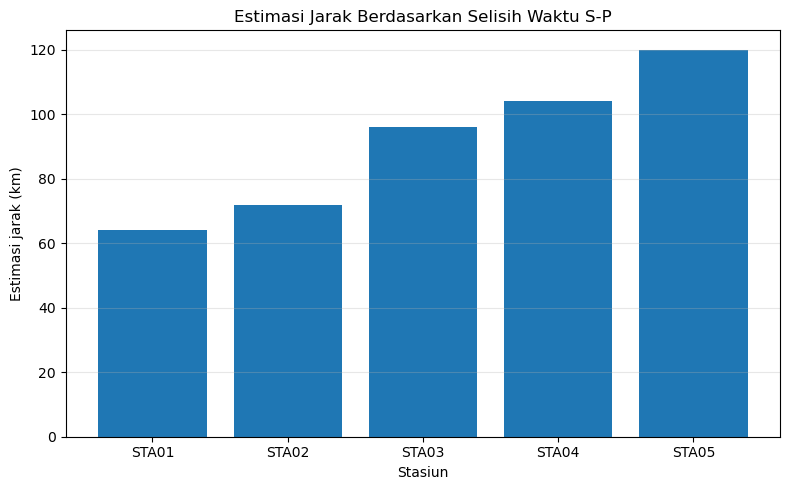

In [22]:
import matplotlib.pyplot as plt

valid_data = seismic_df.loc[valid]

plt.figure(figsize=(8, 5))
plt.bar(
    valid_data["station_id"],
    valid_data["distance_km"]
)

plt.xlabel("Stasiun")
plt.ylabel("Estimasi jarak (km)")
plt.title("Estimasi Jarak Berdasarkan Selisih Waktu S-P")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

seismic_df.to_csv(
    output_dir / "seismic-arrival-audit.csv",
    index=False
)

report_b = f"""# Laporan Recipe R-GEO-001

## Tujuan
Memeriksa waktu tiba gelombang P dan S serta menghitung
estimasi jarak menggunakan konstanta asumsi k = {k} km/s.

## Ringkasan
- Jumlah stasiun: {len(seismic_df)}
- Data valid untuk latihan: {int(valid.sum())}
- Data perlu diperiksa: {int((~valid).sum())}

## Batasan
Data yang digunakan bersifat sintetis. Estimasi jarak tidak
dapat dianggap sebagai hasil penentuan lokasi gempa yang final.
"""

(output_dir / "seismic-arrival-report.md").write_text(
    report_b, encoding="utf-8"
)

print(report_b)
print("Tabel tersimpan:", output_dir / "seismic-arrival-audit.csv")
print("Laporan tersimpan:", output_dir / "seismic-arrival-report.md")

# Laporan Recipe R-GEO-001

## Tujuan
Memeriksa waktu tiba gelombang P dan S serta menghitung
estimasi jarak menggunakan konstanta asumsi k = 8 km/s.

## Ringkasan
- Jumlah stasiun: 5
- Data valid untuk latihan: 5
- Data perlu diperiksa: 0

## Batasan
Data yang digunakan bersifat sintetis. Estimasi jarak tidak
dapat dianggap sebagai hasil penentuan lokasi gempa yang final.

Tabel tersimpan: results\seismic-arrival-audit.csv
Laporan tersimpan: results\seismic-arrival-report.md


In [25]:

pd.testing.assert_frame_equal(
    seismic_original,
    pd.DataFrame(seismic_data)
)

assert (output_dir / "seismic-arrival-audit.csv").exists()
assert (output_dir / "seismic-arrival-report.md").exists()

print("Verifikasi preservasi data: LULUS")
print("Verifikasi file hasil: LULUS")

Verifikasi preservasi data: LULUS
Verifikasi file hasil: LULUS


## Kesimpulan

Recipe 2.4 menunjukkan bagaimana pemeriksaan QA/QC dilakukan secara sistematis sebelum data stasiun digunakan untuk analisis lanjutan. Pemeriksaan dilakukan tanpa menghapus baris atau mengimputasi nilai yang hilang.

Recipe R-GEO-001 merupakan pengembangan untuk bidang Geofisika. Program menghitung selisih waktu tiba gelombang S dan P, mengestimasi jarak berdasarkan konstanta asumsi, serta menandai data yang perlu diperiksa.

Kedua recipe menunjukkan hubungan antara masalah, teori minimum, input, prosedur, hasil, dan pemeriksaan. Hasil hanya berlaku untuk data latihan yang digunakan dalam notebook.

## Referensi

AI Cookbook untuk Earth Sciences. Bagian 2.4, “Recipe sebagai unit praktik”, dan contoh audit station CSV sebelum analisis iklim.

